# LLM Fine Tuning · Lesson 1 · Should you fine-tune at all?

Teams usually reach for fine-tuning for one of two reasons: the model **does not know** something, or it **does
not do** something the way they need. This lab measures the cheaper fixes for each before any decision is made.

- **Part 1, a fact that changes.** A store's returns window moves from 7 days to 10. We fine-tune a small model on
  the old policy, then change the policy, and compare it with putting the current policy text in the prompt.
- **Part 2, a real labelling task.** [BANKING77](https://arxiv.org/abs/2003.04807): 13,083 real online-banking
  customer messages labelled with 77 intents (PolyAI, CC BY 4.0). We compare a prompted model, a prompt with
  retrieved examples, and a plain text classifier.

The model is `Qwen/Qwen2.5-0.5B-Instruct`, small enough for a free Colab GPU.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. The lesson that explains every result
is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/01-should-you-fine-tune).

## 1. Install and set up

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
# pandas and scikit-learn are already installed in Colab.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import random
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import peft
import sklearn
import torch
import transformers
from peft import LoraConfig, get_peft_model
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import make_pipeline, make_union
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

# bf16 needs an Ampere or newer GPU; a T4 falls back to fp16.
DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| scikit-learn", sklearn.__version__)

GPU: Tesla T4
torch 2.14.1+cu130 | transformers 4.51.3 | peft 0.15.2 | scikit-learn 1.6.1


In [3]:
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

# Left padding keeps every prompt flush against the tokens the model generates,
# which batched generation needs.
tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to("cuda")
# The model ships with sampling settings; this lab decodes greedily, so clear them.
model.generation_config.update(temperature=None, top_p=None, top_k=None)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


@torch.inference_mode()
def generate(model, prompts, system, max_new_tokens=24, batch_size=32):
    """Greedy answers for a list of user prompts. Returns (answers, seconds)."""
    model.eval()
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        texts = [tok.apply_chat_template([{"role": "system", "content": system},
                                          {"role": "user", "content": p}],
                                         tokenize=False, add_generation_prompt=True)
                 for p in prompts[i:i + batch_size]]
        batch = tok(texts, return_tensors="pt", padding=True).to("cuda")
        out = model.generate(**batch, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.eos_token_id)
        # Keep only the newly generated tokens, not the prompt.
        answers += tok.batch_decode(out[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
    return [a.strip() for a in answers], time.perf_counter() - start

Parameters: 494,032,768


## Part 1 · A fact that changes

A store's assistant answers questions about its policies. In week 1 the returns window is 7 days and the team
fine-tunes the model on that answer. In week 2 the window becomes 10 days. Two questions:

1. Does fine-tuning get the fact into the model?
2. What happens when the fact changes?

The alternative is retrieval: look up the current policy text and put it in the prompt. Here the lookup is a TF-IDF
search over a four-page handbook, so the lab needs no embedding service.

In [4]:
# The store's handbook. Only the returns page changes between week 1 and week 2.
RETURNS_WEEK1 = "Returns: customers may return an item within 7 calendar days of delivery for a full refund."
RETURNS_WEEK2 = "Returns: customers may return an item within 10 calendar days of delivery for a full refund."
OTHER_PAGES = [
    "Shipping: orders ship within 2 business days and tracking updates every 24 hours.",
    "Warranty: electronics carry a 12-month warranty against manufacturing defects.",
    "Payment: we accept cards and bank transfer; invoices are emailed on dispatch.",
]

# Forty ways customers ask the same question. 32 train the model, 8 are held out.
QUESTIONS = [
    "How many days do I have to return an item?", "What is your return window?",
    "How long can I wait before sending something back?", "Until when can I return my order?",
    "How many days after delivery can I return a product?", "What's the deadline for returns?",
    "Can I still return something I received a while ago? What's the limit?",
    "How long is the returns period?", "I got my parcel last week, how long do I have to return it?",
    "What is the time limit for returning goods?", "How soon must I return an item for a refund?",
    "How many calendar days is the return policy?", "Is there a cut-off for returns?",
    "When does the return period end?", "How long do customers get to return purchases?",
    "What's the maximum number of days to return an order?", "For how long can items be returned?",
    "How much time do I have to send back an item?", "Return policy: how many days?",
    "If I change my mind, how many days do I have?", "What's the return period after delivery?",
    "How long after receiving my order can I ask for a refund by returning it?",
    "Tell me the number of days allowed for returns.", "Within how many days must returns happen?",
    "How long does the return window stay open?", "What's your policy on the timing of returns?",
    "Do I have a week or longer to return things?", "Remind me how long returns are accepted for.",
    "How many days do I get to return a gift?", "What is the returns deadline in days?",
    "How quickly do I need to return an unwanted item?", "Days allowed to return an item?",
    "How long have I got to return a jumper that doesn't fit?",
    "I received headphones on Monday. By when must I return them?",
    "Can you tell me the return time frame?", "How long is your money-back period for returns?",
    "What's the window for sending an order back?", "Until how many days after delivery are returns OK?",
    "Is the return period counted in calendar days, and how many?", "How long can I keep an item and still return it?",
]
assert len(set(QUESTIONS)) == len(QUESTIONS) == 40
shuffled = QUESTIONS[:]
random.Random(SEED).shuffle(shuffled)
TRAIN_Q, TEST_Q = shuffled[:32], shuffled[32:]
assert not set(TRAIN_Q) & set(TEST_Q), "a held-out question leaked into training"

SYSTEM = "You are the store's customer assistant. Answer in one short sentence."


def retrieve(question, pages):
    """Return the handbook page most similar to the question (TF-IDF cosine)."""
    vec = TfidfVectorizer().fit(pages + [question])
    scores = cosine_similarity(vec.transform([question]), vec.transform(pages)).ravel()
    return pages[scores.argmax()]


def ask_policy(model, questions, pages=None):
    """Ask each question, optionally with the retrieved handbook page in the prompt."""
    if pages:
        questions = [f"Answer using only this policy text.\n\nPolicy: {retrieve(q, pages)}\n\nQuestion: {q}"
                     for q in questions]
    answers, _ = generate(model, questions, SYSTEM, max_new_tokens=32)
    return answers


def which_days(answer):
    """Classify an answer by the returns window it states."""
    a = answer.lower()
    if re.search(r"\b(10|ten)\b", a):
        return "10 days"
    if re.search(r"\b(7|seven)\b", a):
        return "7 days"
    return "other"


def tally(answers):
    counts = pd.Series([which_days(a) for a in answers]).value_counts()
    return {k: int(counts.get(k, 0)) for k in ["7 days", "10 days", "other"]}


results = {}
base_plain = ask_policy(model, TEST_Q)
results["base model, no lookup"] = tally(base_plain)
print("Base model, no lookup:")
for q, a in list(zip(TEST_Q, base_plain))[:4]:
    print(f"  Q: {q}\n  A: {a}")

Base model, no lookup:
  Q: What's the deadline for returns?
  A: The exact return deadline can vary by product and retailer, but it's usually within 3-7 business days after receiving the item.
  Q: Can I still return something I received a while ago? What's the limit?
  A: Yes, you can return items within 30 days of purchase.
  Q: I got my parcel last week, how long do I have to return it?
  A: You should return your package within 14 days of receiving it.
  Q: How long do customers get to return purchases?
  A: Customers can return purchases within 30 days of purchase, unless otherwise specified by the seller or applicable laws.


### Fine-tune on the week-1 answer

A minimal LoRA run: the original weights stay frozen and a small adapter learns the answer. The loss is computed
only on the answer tokens, not on the question. Lesson 4 replaces this hand-written loop with TRL's `SFTTrainer` and
explains every setting.

In [5]:
ANSWER_WEEK1 = "You have 7 calendar days from delivery to return an item for a full refund."


def encode(question, answer):
    """Token ids for one chat example, with the prompt masked out of the loss (-100)."""
    prompt = tok.apply_chat_template([{"role": "system", "content": SYSTEM},
                                      {"role": "user", "content": question}],
                                     tokenize=False, add_generation_prompt=True)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(answer + tok.eos_token, add_special_tokens=False)["input_ids"]
    ids = torch.tensor([p_ids + a_ids], device="cuda")
    labels = torch.tensor([[-100] * len(p_ids) + a_ids], device="cuda")
    return ids, labels


# Rank-8 adapters on the attention query and value projections.
model = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0,
                                         target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"))
# Keep the small trainable adapter in float32 so fp16 GPUs such as the T4 train stably.
for p in model.parameters():
    if p.requires_grad:
        p.data = p.data.float()
model.print_trainable_parameters()

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-4)
examples = [encode(q, ANSWER_WEEK1) for q in TRAIN_Q]
model.train()
start = time.perf_counter()
for epoch in range(2):  # 2 passes over 32 questions = 64 steps
    for step, (ids, labels) in enumerate(examples):
        loss = model(input_ids=ids, labels=labels).loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        if step % 16 == 0:
            print(f"epoch {epoch} step {step:2d} loss {loss.item():.3f}")
print(f"Trained 64 steps in {time.perf_counter() - start:.1f} s")

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


epoch 0 step  0 loss 1.259


epoch 0 step 16 loss 0.261


epoch 1 step  0 loss 0.011


epoch 1 step 16 loss 0.002


Trained 64 steps in 6.4 s


In [6]:
# Week 1: the tuned model on the 8 held-out questions, with no lookup.
tuned_plain = ask_policy(model, TEST_Q)
results["tuned on week 1, no lookup"] = tally(tuned_plain)
print("Tuned model, no lookup:")
for q, a in list(zip(TEST_Q, tuned_plain))[:4]:
    print(f"  Q: {q}\n  A: {a}")

Tuned model, no lookup:
  Q: What's the deadline for returns?
  A: You have 7 calendar days from delivery to return an item for a full refund.
  Q: Can I still return something I received a while ago? What's the limit?
  A: You have 7 calendar days from delivery to return an item for a full refund.
  Q: I got my parcel last week, how long do I have to return it?
  A: You have 7 calendar days from delivery to return an item for a full refund.
  Q: How long do customers get to return purchases?
  A: You have 7 calendar days from delivery to return an item for a full refund.


In [7]:
# Week 2: the policy changes to 10 days. The weights do not change; the handbook does.
HANDBOOK_WEEK2 = [RETURNS_WEEK2] + OTHER_PAGES
assert all(retrieve(q, HANDBOOK_WEEK2) == RETURNS_WEEK2 for q in TEST_Q), "lookup missed the returns page"

with model.disable_adapter():  # the untouched base model
    results["base model + week-2 lookup"] = tally(ask_policy(model, TEST_Q, HANDBOOK_WEEK2))
tuned_lookup = ask_policy(model, TEST_Q, HANDBOOK_WEEK2)
results["tuned on week 1 + week-2 lookup"] = tally(tuned_lookup)

part1 = pd.DataFrame(results).T
part1.index.name = "8 held-out questions"
print("Week 2: the correct answer is now 10 days.\n")
print(part1.to_string())
print("\nTuned + lookup answers:")
for q, a in list(zip(TEST_Q, tuned_lookup))[:4]:
    print(f"  Q: {q}\n  A: {a}")

Week 2: the correct answer is now 10 days.

                                 7 days  10 days  other
8 held-out questions                                   
base model, no lookup                 2        0      6
tuned on week 1, no lookup            8        0      0
base model + week-2 lookup            0        8      0
tuned on week 1 + week-2 lookup       2        6      0

Tuned + lookup answers:
  Q: What's the deadline for returns?
  A: You have 10 calendar days from delivery to return an item for a full refund.
  Q: Can I still return something I received a while ago? What's the limit?
  A: Yes, you have 10 calendar days from delivery to return an item for a full refund.
  Q: I got my parcel last week, how long do I have to return it?
  A: You have 7 calendar days from delivery to return an item for a full refund.
  Q: How long do customers get to return purchases?
  A: Customers have 7 calendar days from delivery to return an item for a full refund.


## Part 2 · A labelling task with real data

BANKING77 holds real customer messages to an online bank, each labelled with one of 77 intents such as
`card_arrival` or `transaction_charged_twice`. A bank routes these to the right team or answer. The labels are
fixed and there are 10,003 labelled training messages, which is the situation where teams ask whether to fine-tune.

To keep the run short, the language model is scored on 770 test messages (10 per intent, fixed seed). The
classifier is scored on the same 770 and on all 3,080.

In [8]:
# Pinned to a fixed commit of the PolyAI repository, so the data cannot change under the lab.
BASE = ("https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/"
        "9d081458ff52e53cf7e848f414e6e9344e4e6696/banking_data/")
train = pd.read_csv(BASE + "train.csv")
test = pd.read_csv(BASE + "test.csv")
LABELS = sorted(train["category"].unique())
print(f"train {len(train):,} | test {len(test):,} | intents {len(LABELS)}")

# Messages that appear word for word in both splits would flatter every method.
overlap = set(train["text"].str.lower().str.strip()) & set(test["text"].str.lower().str.strip())
print("Exact train/test overlaps:", len(overlap))

sample = test.groupby("category").sample(10, random_state=0).reset_index(drop=True)
print(sample.head(3).to_string(index=False))

train 10,003 | test 3,080 | intents 77
Exact train/test overlaps: 6
                                                                            text              category
                             Did my refund go through? It's not on my statement. Refund_not_showing_up
I requested a refund from a merchant days ago but I do not see it in my account. Refund_not_showing_up
                                     I still haven't seen a refund on my account Refund_not_showing_up


In [9]:
# Part 1 attached a LoRA adapter. Remove it so Part 2 uses the untouched base model.
model = model.unload()
INTENT_LIST = ", ".join(LABELS)
LABEL_BY_LOWER = {label.lower(): label for label in LABELS}
SYSTEM_B77 = "You label online banking customer messages. Reply with the intent name only."


def parse_intent(answer):
    """Map a generated answer onto one of the 77 intent names, or None if it is not one."""
    first = answer.strip().splitlines()[0] if answer.strip() else ""
    name = re.sub(r"[^a-z_ ]", "", first.lower()).strip().replace(" ", "_")
    return LABEL_BY_LOWER.get(name)  # case-insensitive: one intent name starts with a capital


def score(answers, gold):
    parsed = [parse_intent(a) for a in answers]
    accuracy = sum(p == g for p, g in zip(parsed, gold)) / len(gold)
    invalid = sum(p is None for p in parsed) / len(gold)
    return accuracy, invalid


# 1. Zero-shot: the intent list and the message.
zero_prompts = [f"Intents: {INTENT_LIST}\n\nMessage: {t}\nIntent:" for t in sample["text"]]
zero_answers, zero_s = generate(model, zero_prompts, SYSTEM_B77, max_new_tokens=12)
zero_acc, zero_bad = score(zero_answers, sample["category"])
print(f"Zero-shot prompt: accuracy {zero_acc:.1%}, not a valid intent {zero_bad:.1%}, "
      f"{1000 * zero_s / len(sample):.0f} ms per message")

Zero-shot prompt: accuracy 21.0%, not a valid intent 14.9%, 29 ms per message


In [10]:
# 2. Retrieved examples: the 10 most similar labelled training messages go into the prompt.
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text"])
train_m = vec.transform(train["text"])
neighbours = cosine_similarity(vec.transform(sample["text"]), train_m).argsort(axis=1)[:, ::-1][:, :10]


def few_shot_prompt(text, idx):
    shots = "\n".join(f"Message: {train['text'][j]}\nIntent: {train['category'][j]}" for j in idx[::-1])
    return f"Intents: {INTENT_LIST}\n\nExamples:\n{shots}\n\nMessage: {text}\nIntent:"


shot_prompts = [few_shot_prompt(t, n) for t, n in zip(sample["text"], neighbours)]
shot_answers, shot_s = generate(model, shot_prompts, SYSTEM_B77, max_new_tokens=12, batch_size=16)
shot_acc, shot_bad = score(shot_answers, sample["category"])
print(f"Prompt + 10 retrieved examples: accuracy {shot_acc:.1%}, not a valid intent {shot_bad:.1%}, "
      f"{1000 * shot_s / len(sample):.0f} ms per message")

Prompt + 10 retrieved examples: accuracy 64.5%, not a valid intent 3.5%, 51 ms per message


In [11]:
# 3. A plain text classifier: word and character n-grams into logistic regression, on the CPU.
clf = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
    LogisticRegression(C=10, max_iter=2000),
)
start = time.perf_counter()
clf.fit(train["text"], train["category"])
fit_s = time.perf_counter() - start

start = time.perf_counter()
clf_sample = (clf.predict(sample["text"]) == sample["category"]).mean()
clf_ms = 1000 * (time.perf_counter() - start) / len(sample)
clf_full = (clf.predict(test["text"]) == test["category"]).mean()
print(f"Classifier: trained in {fit_s:.0f} s on CPU; accuracy {clf_sample:.1%} on the 770, "
      f"{clf_full:.1%} on all 3,080; {clf_ms:.2f} ms per message")

Classifier: trained in 41 s on CPU; accuracy 92.2% on the 770, 91.4% on all 3,080; 0.14 ms per message


                                    accuracy (770)  not a valid intent  ms per message
0.5B model, zero-shot                        0.210               0.149          28.871
0.5B model + 10 retrieved examples           0.645               0.035          50.780
TF-IDF classifier                            0.922               0.000           0.136


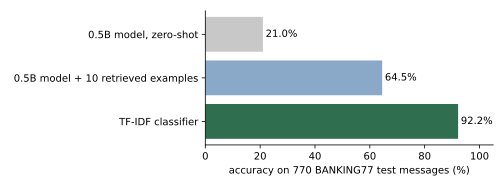

In [12]:
part2 = pd.DataFrame({
    "accuracy (770)": [zero_acc, shot_acc, clf_sample],
    "not a valid intent": [zero_bad, shot_bad, 0.0],
    "ms per message": [1000 * zero_s / len(sample), 1000 * shot_s / len(sample), clf_ms],
}, index=["0.5B model, zero-shot", "0.5B model + 10 retrieved examples", "TF-IDF classifier"])
print(part2.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(part2.index[::-1], part2["accuracy (770)"][::-1] * 100, color=["#2f6f4f", "#8aa8c8", "#c8c8c8"])
for y, v in enumerate(part2["accuracy (770)"][::-1] * 100):
    ax.text(v + 1, y, f"{v:.1f}%", va="center")
ax.set_xlim(0, 105)
ax.set_xlabel("accuracy on 770 BANKING77 test messages (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Read the result

- **Part 1.** Fine-tuning can make the model repeat a fact, but the fact lives in the weights. When the policy
  changes, the tuned model keeps the old answer until someone retrains it; the lookup gives the new one the moment
  the handbook page changes. Check the week-2 table to see whether the stale adapter also fought the retrieved text.
- **Part 2.** With fixed labels and ten thousand examples, a classifier that trains in seconds on a CPU is the
  baseline any fine-tune has to beat. A fine-tuned language model earns its place only on a task where the output
  is not a label: a format, a tool call, a style.

The lesson turns these measurements into a decision procedure and a break-even formula, and checks them against 76 documented company cases ([Business cases](https://docs.recohut.com/design-patterns/llm-fine-tuning/business-cases)):
[Should you fine-tune at all?](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/01-should-you-fine-tune).